In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# words = open('./Chinese-Names-Corpus/Chinese_Names_Corpus/Ancient_Names_Corpus.txt', 'r').read().splitlines()
# words = words[2:]
words = open('./makemore/names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)
vocab_size = len(stoi)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [3]:
block_size = 4

def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            idx = stoi[ch]
            X.append(context)
            Y.append(idx)
            context = context[1:] + [idx]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


In [4]:
n_embd = 20
n_hidden = 300
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g) * (5/3) / ((n_embd * block_size) ** 0.5)
# b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1, n_hidden));
bnbias = torch.zeros((1, n_hidden));
bnmean_running = torch.ones((1, n_hidden));
bnstd_running = torch.zeros((1, n_hidden));

# parameters = [C, W1, b1, W2, b2, bngain, bnbias]
parameters = [C, W1, W2, b2, bngain, bnbias]

for p in parameters:
    p.requires_grad = True
    
sum(p.nelement() for p in parameters)

33267

In [ ]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lri = []
lossi = []

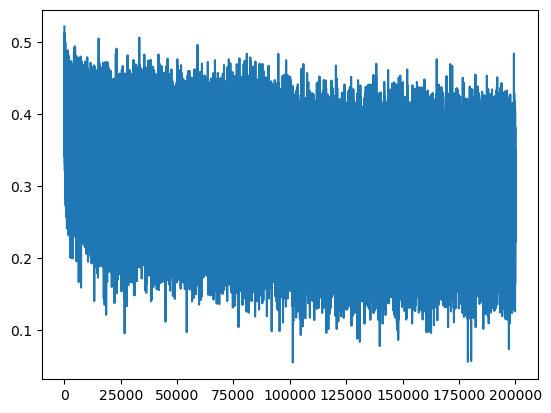

In [6]:
batch_size = 32
max_steps = 200000

for i in range(max_steps):
    # mini batch construct
    idx = torch.randint(0, Xtr.shape[0], (batch_size,)) # batch_size = n

    # forward pass
    emb = C[Xtr[idx]] # Xtr[idx]    shape = n, 5
                      # C[Xtr[idx]] shape = n, 5, 20
                      
    # batch normalization
    hpreact = emb.view(-1, block_size * n_embd) @ W1
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    hpreact = torch.tanh(hpreact)

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    logits = hpreact @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[idx])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    if i < 100000:
        lr = 0.1
    elif i < 200000:
        lr = 0.01
    elif i < 300000:
        lr = 0.005
    else:
        lr = 0.001

    for p in parameters:
        p.data += -lr * p.grad

    # # track stats
    # lri.append(lre[i])
    lossi.append(loss.log10().item())

plt.plot(lossi)

In [7]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train' : (Xtr, Ytr),
        'dev' : (Xdev, Ydev),
        'test' : (Xte, Yte)
    }[split]

    emb = C[x]
    hpreact = emb.view(-1, block_size * n_embd) @ W1 #  + b1
    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('dev')

# train 1.9090852737426758
# dev 2.023937463760376

train 1.9086133241653442
dev 2.0249218940734863


In [8]:

# print(loss.item())
# g = torch.Generator().manual_seed(42)
g = torch.Generator().manual_seed(2147483647+10)

for i in range(20):
    context = [0] * (block_size)
    # context += [stoi['夏']]
    out = []
    while True:
        x = C[torch.tensor(context)]
        # hpreact = torch.tanh(x.view(1, -1) @ W1 + b1)
        hpreact = x.view(1, -1) @ W1 # + b1
        hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running)
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        probs = torch.softmax(logits, dim=1)
        idx = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [idx]
        if idx == 0:
            break
        out.append(itos[idx])

    print(''.join(out))


carlah
quinley
fitmy
xithty
skarlene
mahnel
quetzac
kaquille
mari
chaiiv
kaleigh
hamond
jaquinton
lilla
jaquial
jermaijarinity
jennix
demet
faiga
gilefey
